In [1]:
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import skimage as ski

import numpy.ma as ma
# import cupy as cp

import scipy as sp

import statistics as st

from itertools import cycle

# from sklearn.preprocessing import minmax_scale
import pandas as pd

from scipy import ndimage as ndi
from skimage.feature import peak_local_max

import mpl_toolkits as mpl

from pathlib import Path

import seaborn as sns


In [2]:
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams['figure.figsize'] = [6.4, 4.9]

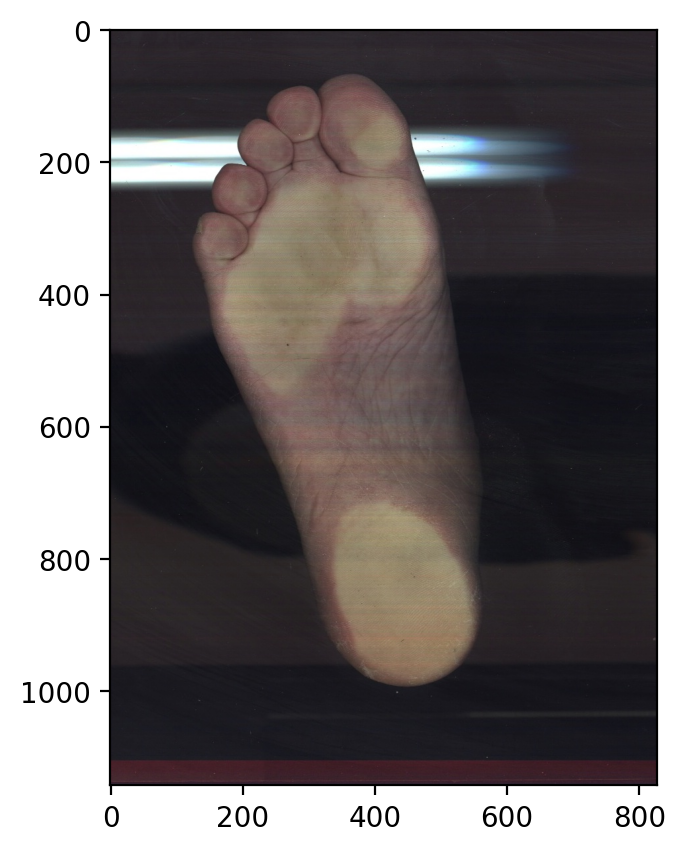

In [3]:
image = cv.imread('../обработка изображений/плантограммы/row1_Сканирование 11_12_photo1.jpg', cv.IMREAD_UNCHANGED)

image = cv.cvtColor(image, cv.COLOR_BGR2RGB)

plt.imshow(image)

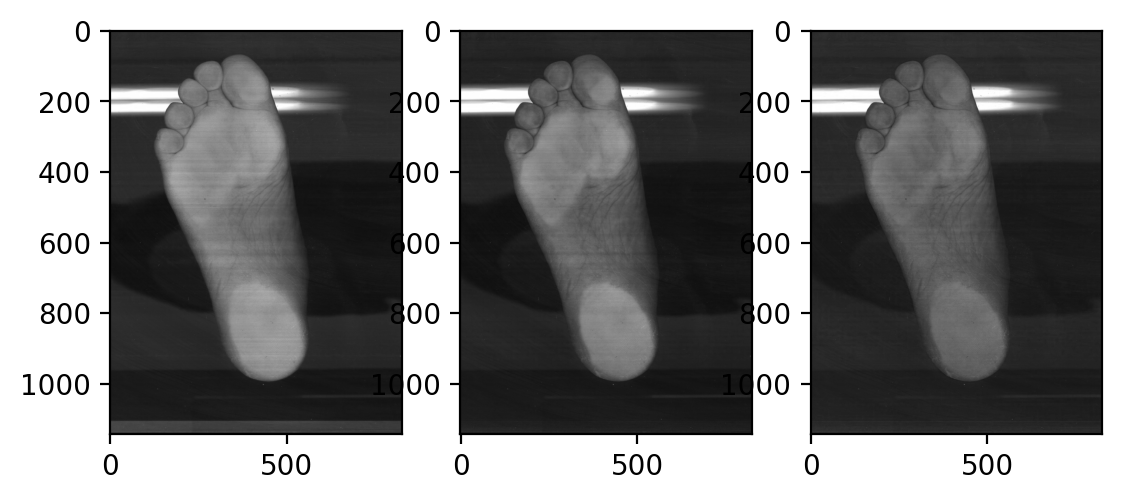

In [4]:
r, g, b = image[...,0], image[...,1], image[...,2]

fig, axs = plt.subplots(1, 3)

axs[0].imshow(r, 'gray')
axs[1].imshow(g, 'gray')
axs[2].imshow(b, 'gray')

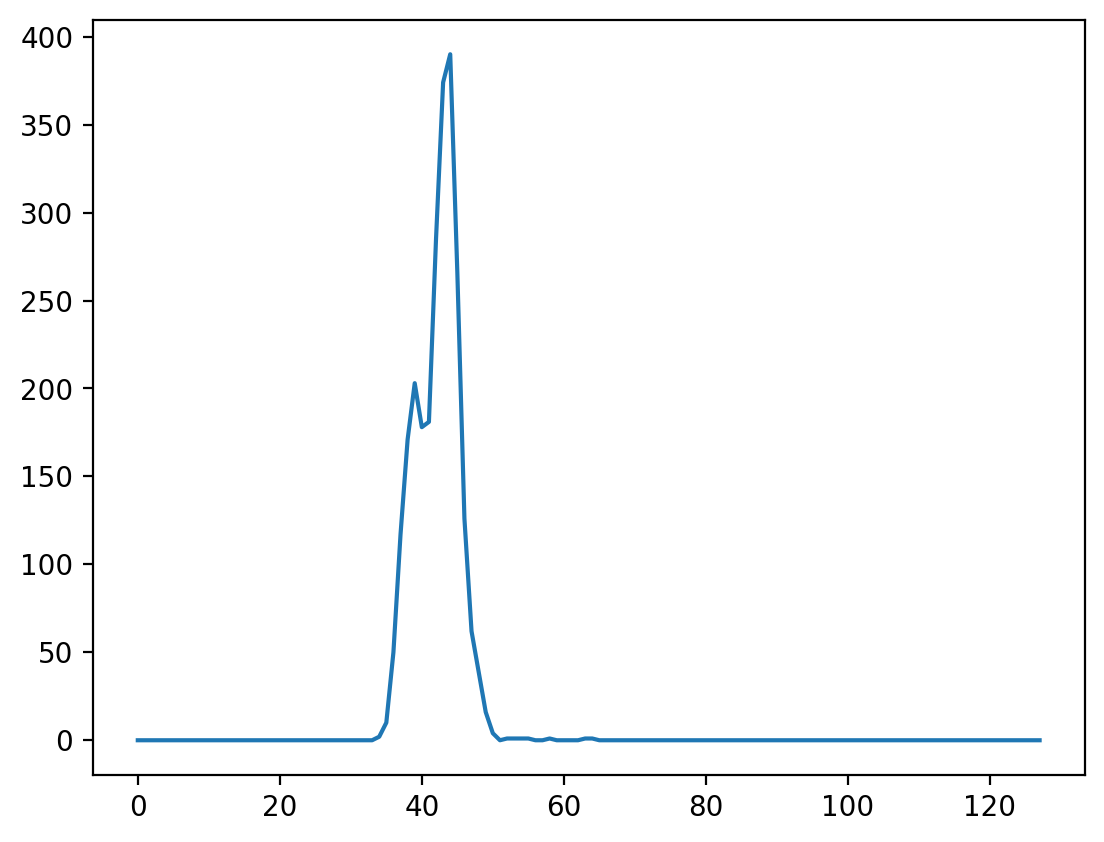

In [5]:
##### gray = cv.cvtColor(image, cv.COLOR_RGB2GRAY)

# plt.hist(gray)
histSize = 128

rHist = cv.calcHist(image, [2], None, [histSize], [0, histSize])

plt.plot(range(0,histSize), rHist)

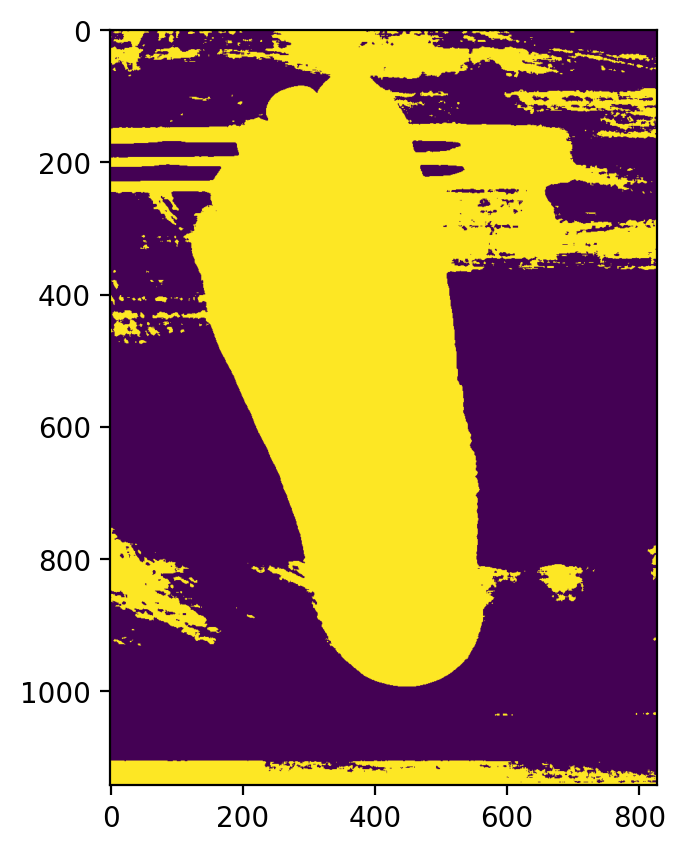

In [6]:

image2 = image.copy()
image2 = cv.medianBlur(image2, 5)

gray = cv.cvtColor(image2, cv.COLOR_RGB2GRAY)

mask = (gray > 40) & (gray < 240)

colorMask = np.repeat(np.expand_dims(mask, 2), 3, axis=2)

image2[~colorMask] = 0

plt.imshow(mask)

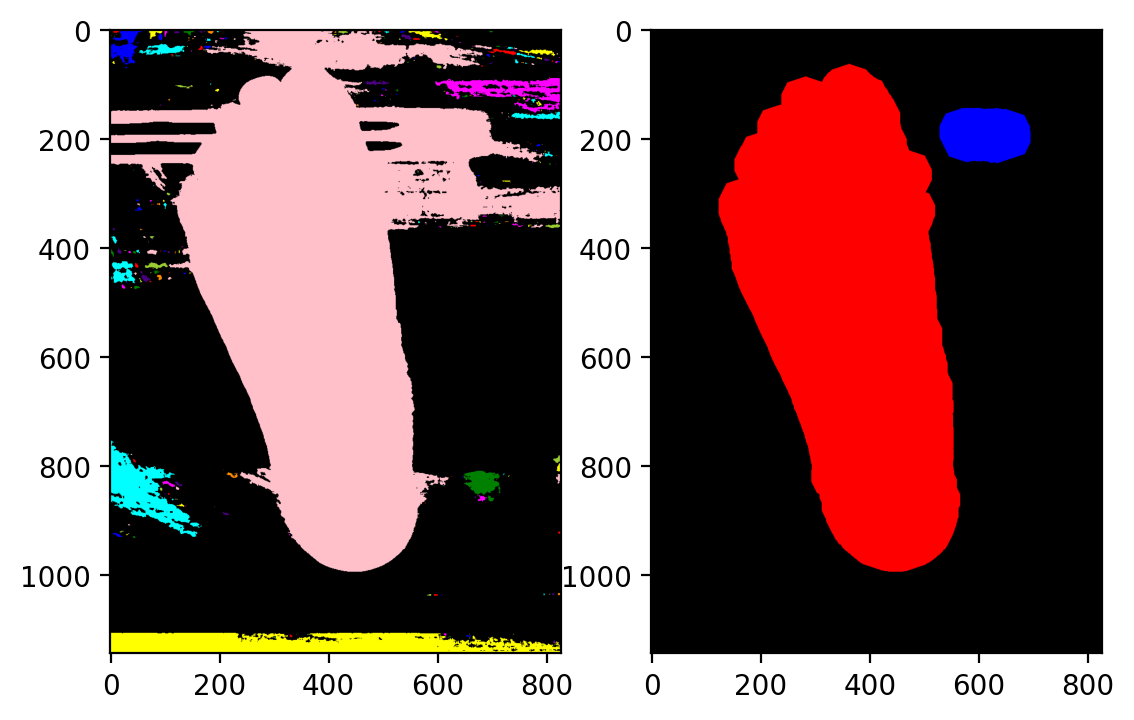

In [7]:
# mask[0:300, 0:500]
mask2 = np.asarray(mask.copy(), np.uint8)
labels = ski.measure.label(mask2)

fig, axs = plt.subplots(1, 2)

axs[0].imshow(ski.color.label2rgb(labels))

mask2 = cv.morphologyEx(mask2, cv.MORPH_OPEN, cv.getStructuringElement(cv.MORPH_ELLIPSE, (9, 9)), iterations=10)

axs[1].imshow(ski.color.label2rgb(ski.measure.label(mask2)))

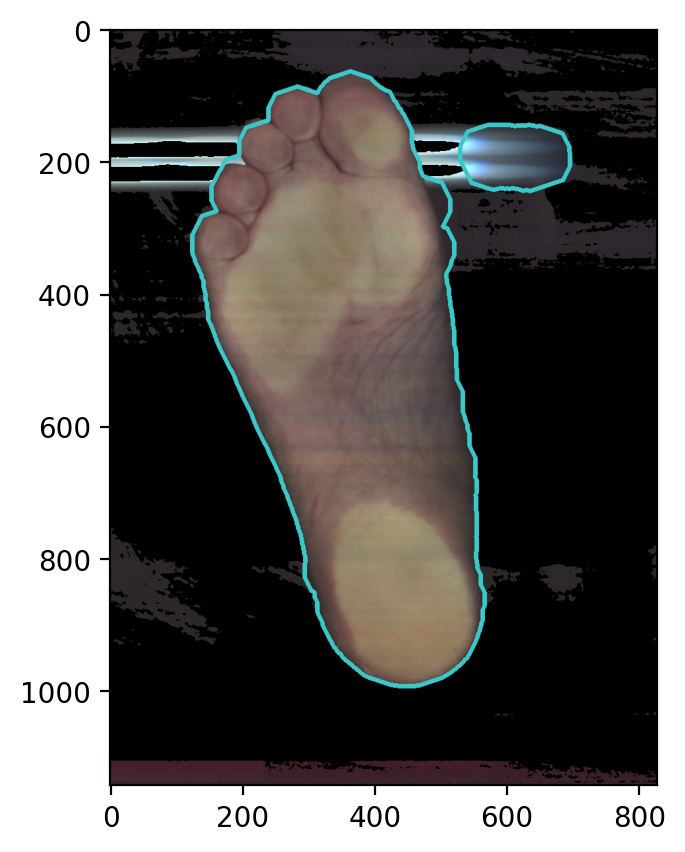

In [8]:
labels = ski.measure.label(mask2)

roi = ski.measure.regionprops(labels)[0]
y1, x1, y2, x2 = roi.bbox

# roi = image2[y1:y2, x1:x2]
# plt.imshow(roi)

contour = cv.findContours(mask2, cv.RETR_LIST, cv.CHAIN_APPROX_SIMPLE)[0]

plt.imshow(cv.drawContours(image2, contour, -1, (60, 200, 200), 5))


In [9]:

gray = cv.cvtColor(roi, cv.COLOR_RGB2GRAY)

mask = (gray > 100) & (gray < 130)

mask = np.astype(mask, np.uint8)

mask = cv.morphologyEx(mask, cv.MORPH_OPEN, cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3)), iterations=3)

plt.imshow(ski.color.label2rgb(ski.measure.label(mask)))

error: OpenCV(4.13.0) :-1: error: (-5:Bad argument) in function 'cvtColor'
> Overload resolution failed:
>  - src is not a numpy array, neither a scalar
>  - Expected Ptr<cv::UMat> for argument 'src'


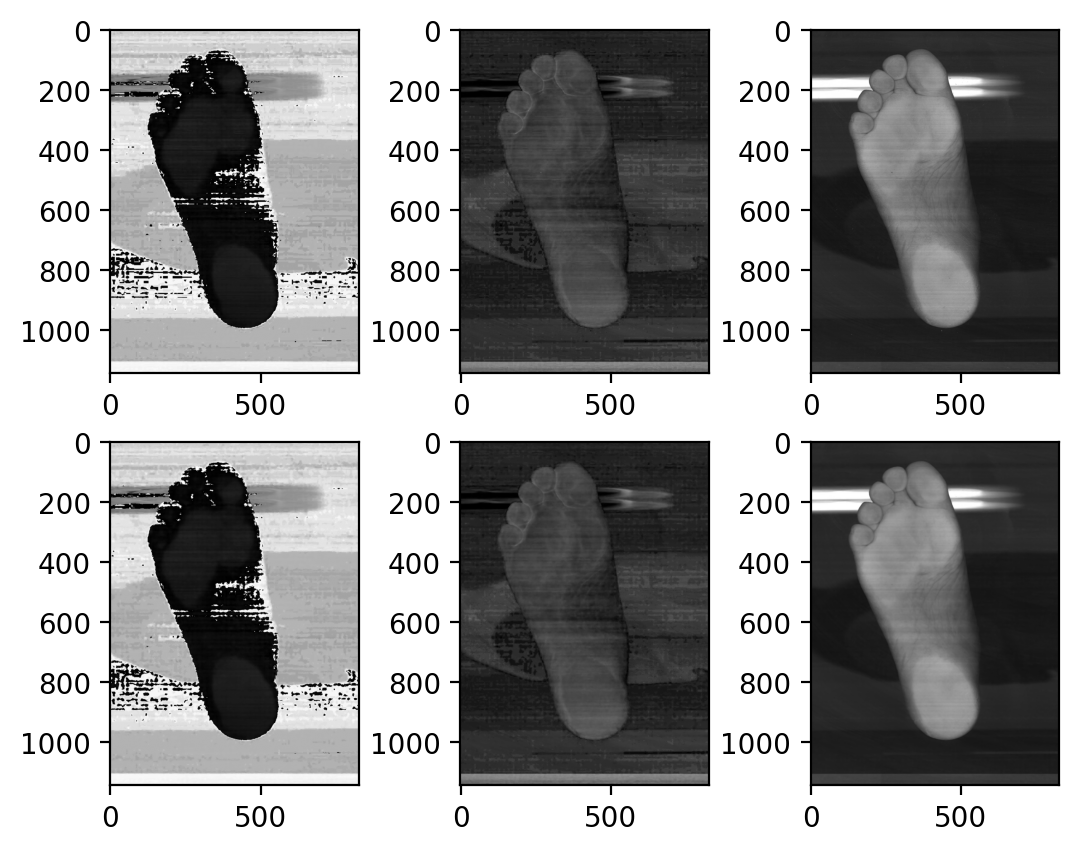

In [10]:
image3 = image.copy()

hsv = cv.cvtColor(image3, cv.COLOR_RGB2HSV)
h, s, v = hsv[...,0], hsv[...,1], hsv[...,2]

fig, axs = plt.subplots(2, 3)
axs = axs.flatten()

axs[0].imshow(h, 'gray')
axs[1].imshow(s, 'gray')
axs[2].imshow(v, 'gray')

image3 = cv.medianBlur(image3, 5)
hsv = cv.cvtColor(image3, cv.COLOR_RGB2HSV)
h, s, v = hsv[...,0], hsv[...,1], hsv[...,2]

axs[3].imshow(h, 'gray')
axs[4].imshow(s, 'gray')
axs[5].imshow(v, 'gray')

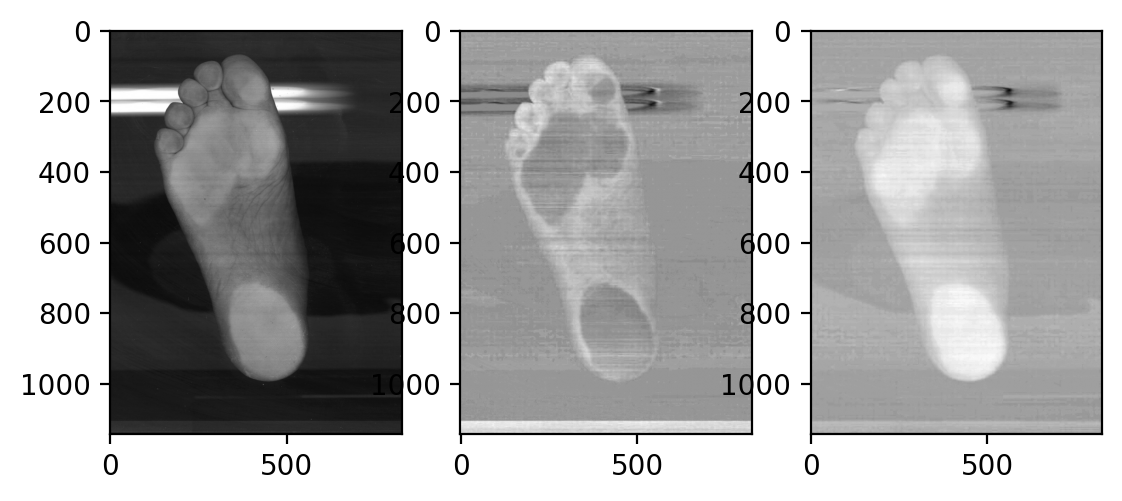

In [11]:
lab = cv.cvtColor(image, cv.COLOR_RGB2Lab)
l, a, b = lab[...,0], lab[...,1], lab[...,2]

fig, axs = plt.subplots(1, 3)

axs[0].imshow(l, 'gray')
axs[1].imshow(a, 'gray')
axs[2].imshow(b, 'gray')

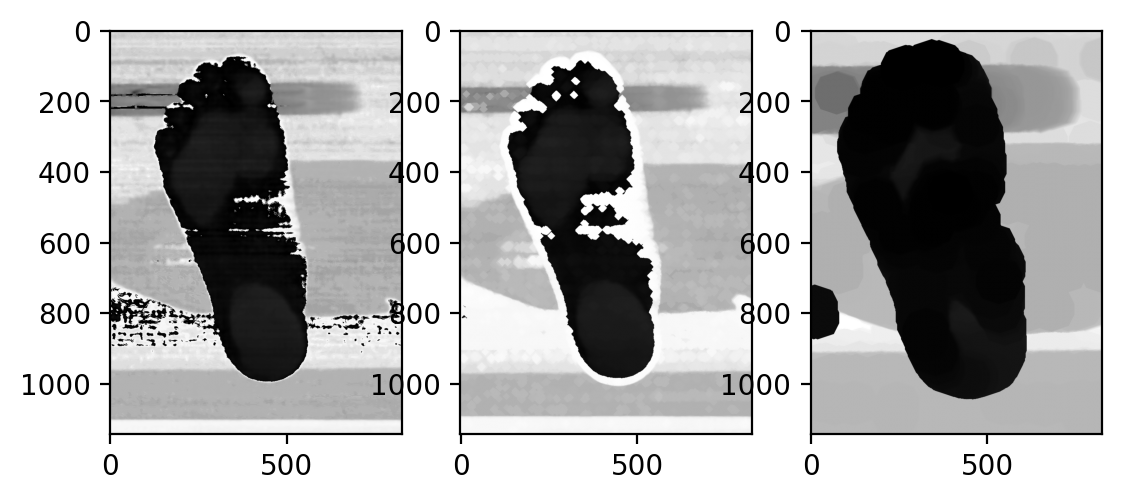

In [12]:
# axs[3].imshow(cv.convertScaleAbs(cv.Laplacian(h, cv.CV_16S, 3)), 'gray')
image3 = image.copy()

image3 = cv.GaussianBlur(image3, (15, 15), 3)

hsv = cv.cvtColor(image3, cv.COLOR_RGB2HSV)
h, s, v = hsv[...,0], hsv[...,1], hsv[...,2]

fig, axs = plt.subplots(1, 3)
axs = axs.flatten()

dim = 39
ksize = (dim, dim)
shape = cv.getStructuringElement(cv.MORPH_ELLIPSE, ksize)

smoothed = cv.morphologyEx(h, cv.MORPH_CLOSE, shape, iterations=1)
dim = 3
ksize = (dim, dim)
shape = cv.getStructuringElement(cv.MORPH_ELLIPSE, ksize)

smoothed = cv.morphologyEx(h, cv.MORPH_DILATE, shape, iterations=10)

dim = 9
ksize = (dim, dim)
shape = cv.getStructuringElement(cv.MORPH_ELLIPSE, ksize)

smoothed2 = cv.morphologyEx(smoothed, cv.MORPH_ERODE, shape, iterations=15)

axs[0].imshow(h, 'gray')
axs[1].imshow(smoothed, 'gray')
axs[2].imshow(smoothed2, 'gray')
# axs[1].imshow(np.astype(smoothed2 < 80, np.uint8) - np.astype(smoothed < 80, np.uint8), 'gray')
# axs[1].imshow(np.astype(smoothed2 > 80, np.uint8), 'gray')
# cv.imwrite('../exported/smoothed.png', smoothed)
# axs[2].imshow(v, 'gray')

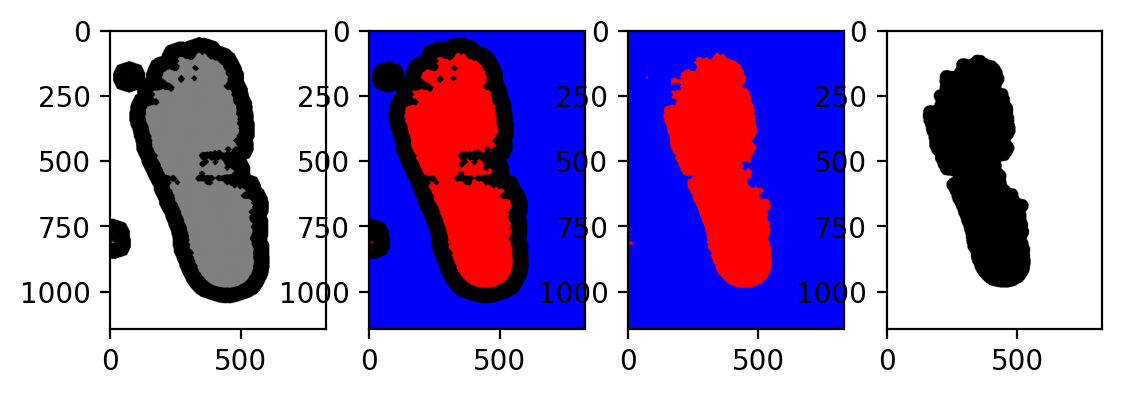

In [13]:
image4 = image.copy()

markers = np.astype(smoothed < 80, np.uint8)

fig, axs = plt.subplots(1, 4)
axs = axs.flatten()


image4 = cv.GaussianBlur(image, (3, 3), 1)

lab = cv.cvtColor(image4, cv.COLOR_RGB2Lab)
l, a, b = lab[...,0], lab[...,1], lab[...,2]
# l[l > 200] = 0

markers[smoothed2 > 80] = 2
axs[0].imshow(markers, 'gray')
segmentedLabels = ski.segmentation.watershed(l, markers=markers)

# axs[1].imshow(l, 'gray')
axs[1].imshow(ski.color.label2rgb(markers))
axs[2].imshow(ski.color.label2rgb(segmentedLabels))


dim = 25
ksize = (dim, dim)
shape = cv.getStructuringElement(cv.MORPH_ELLIPSE, ksize)

segmentedLabels = cv.morphologyEx(segmentedLabels, cv.MORPH_CLOSE, shape, iterations=2)
axs[3].imshow(segmentedLabels, 'gray')

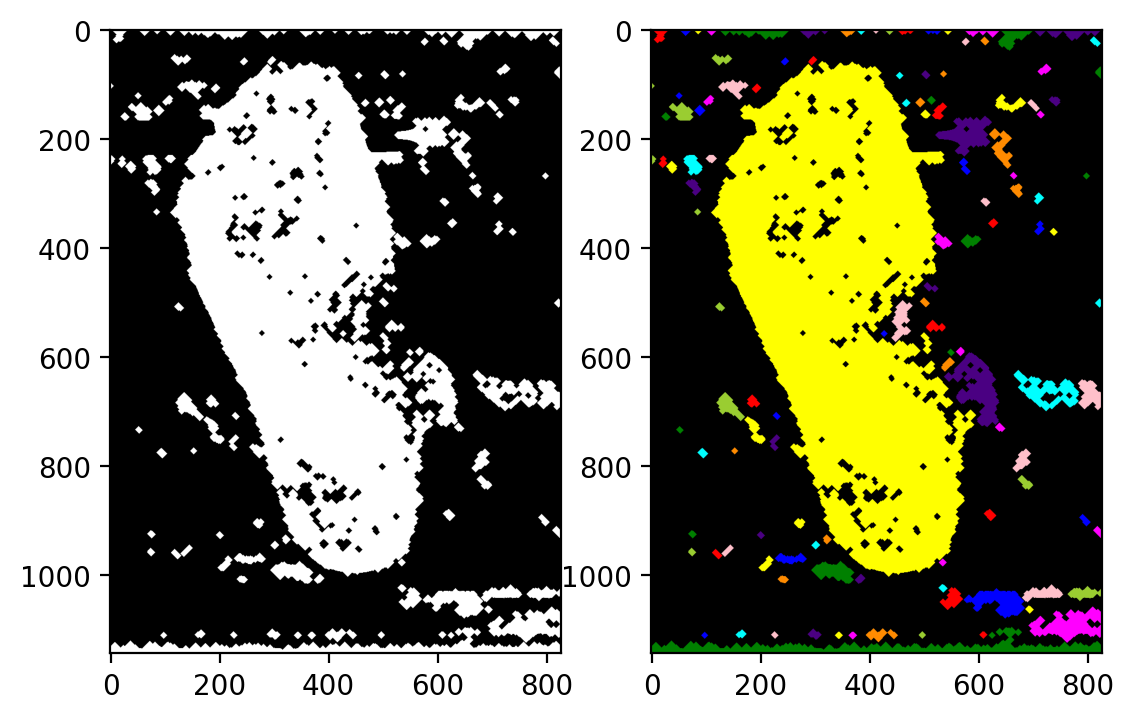

In [40]:
# axs[3].imshow(cv.convertScaleAbs(cv.Laplacian(h, cv.CV_16S, 3)), 'gray')
image3 = image.copy()

image3 = cv.GaussianBlur(image3, (3, 3), 9)

hsv = cv.cvtColor(image3, cv.COLOR_RGB2HSV)
h, s, v = hsv[...,0], hsv[...,1], hsv[...,2]

r, g, b = image3[...,0], image3[..., 1], image3[..., 2]

lab = cv.cvtColor(image3, cv.COLOR_RGB2Lab)
l, a, b = lab[...,0], lab[...,1], lab[...,2]


fig, axs = plt.subplots(1, 2)
axs = axs.flatten()

dim = 3
ksize = (dim, dim)

l[l >= 180] = 0

channel = l

edges = cv.convertScaleAbs(cv.Laplacian(channel, cv.CV_16S, ksize=3))

shape = cv.getStructuringElement(cv.MORPH_ELLIPSE, ksize)

# channel = np.astype(edges > 5, np.uint8)

# edges = cv.morphologyEx(channel, cv.MORPH_OPEN, shape, iterations=2)

edges = np.astype(edges > 10, np.uint8)

# edges = cv.normalize(np.exp(edges), 0, 255, cv.NORM_MINMAX, dtype=cv.CV_8U)


edges2 = cv.morphologyEx(edges, cv.MORPH_CLOSE, shape, iterations=5)

# shape = np.array([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]).T
edges2 = cv.morphologyEx(edges2, cv.MORPH_OPEN, shape, iterations=6)

# edges3 = cv.filter2D(edges2, cv.CV_8U, shape)


axs[0].imshow(edges2, 'gray')
# axs[1].imshow(np.astype(edges2 & edges3, np.uint8), 'gray'edges2 - edges3)
# axs[1].imshow(edges2, 'gray')
axs[1].imshow(ski.color.label2rgb(ski.measure.label(edges2)), 'gray')

# axs[2].imshow(v, 'gray')



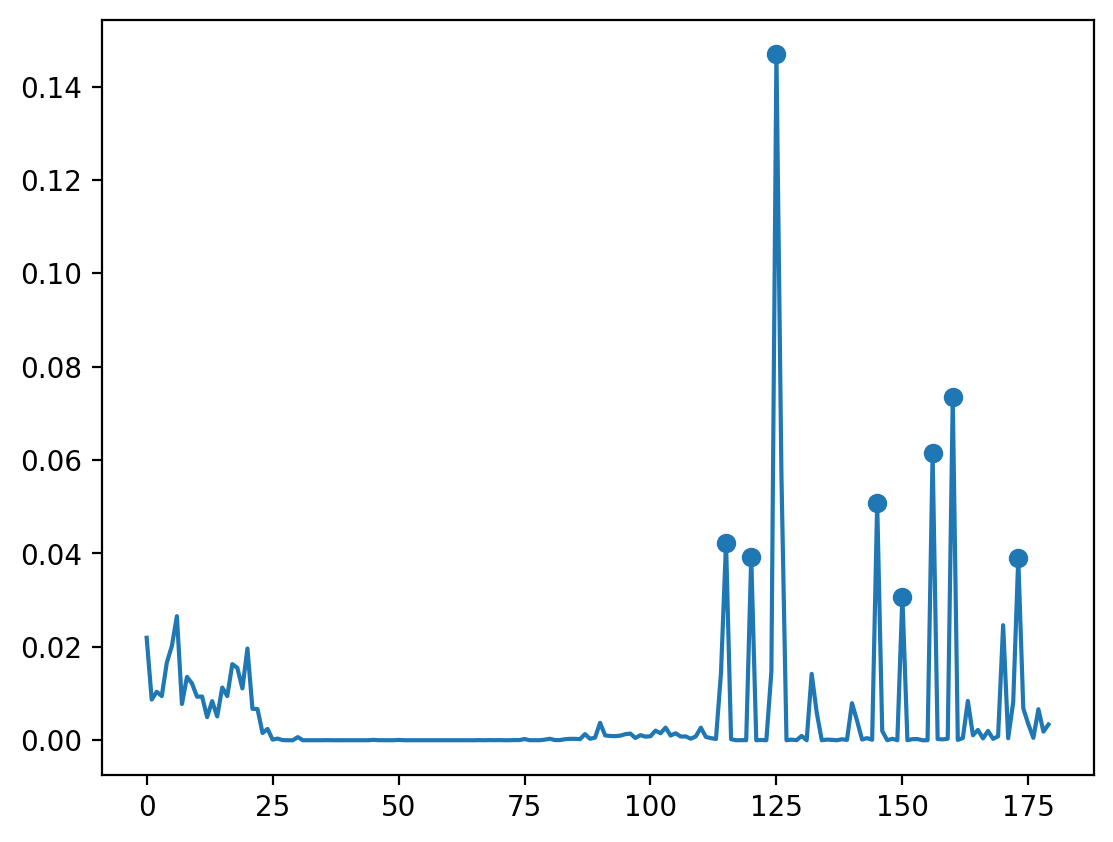

In [15]:
# axs[3].imshow(cv.convertScaleAbs(cv.Laplacian(h, cv.CV_16S, 3)), 'gray')
image3 = image.copy()

hsv = cv.cvtColor(image3, cv.COLOR_RGB2HSV)
h, s, v = hsv[...,0], hsv[...,1], hsv[...,2]

fig, axs = plt.subplots(1)
# axs = axs.flatten()
axs = axs

# am = axs[0].imshow(h, 'gray')
# fig.colorbar(am)

hist, hist_centers = ski.exposure.histogram(h, normalize=True)

axs.plot(hist_centers, hist)
# print(len(hist))
# axs.plot(hist)
# plt.grid(which='major')

peaks, _ = sp.signal.find_peaks(hist, threshold=0.02,distance=4)


axs.scatter(peaks, hist[peaks])


2 0
8
0 115
1 120
2 125
3 145
4 150
5 156
6 160
7 173


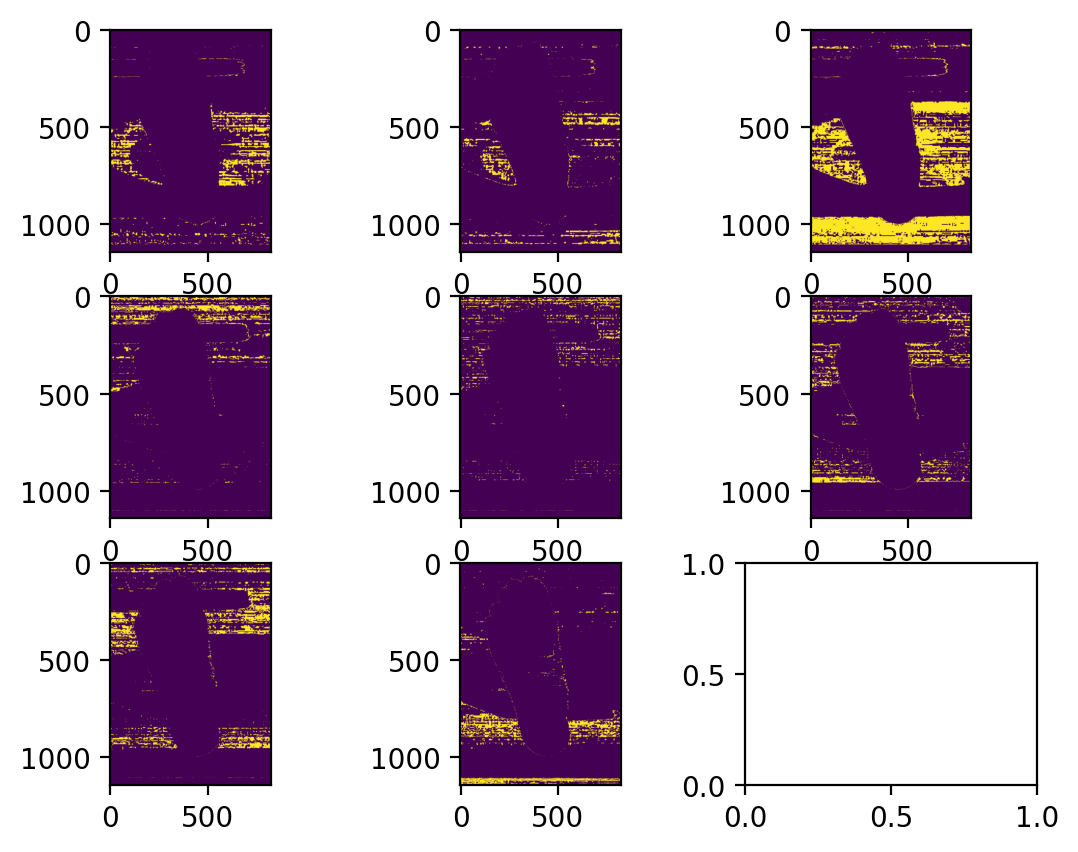

In [16]:
cols = len(peaks) % 4
rows = len(peaks) // 4
print(rows, cols)
print(len(peaks))

fig, axs = plt.subplots(3, 3)
axs = axs.flatten()

for i, peak in enumerate(peaks):
    print(i, peak)
    center = peak
    width = 2
    axs[i].imshow(((center - width) < h ) & (h < (center + width)))

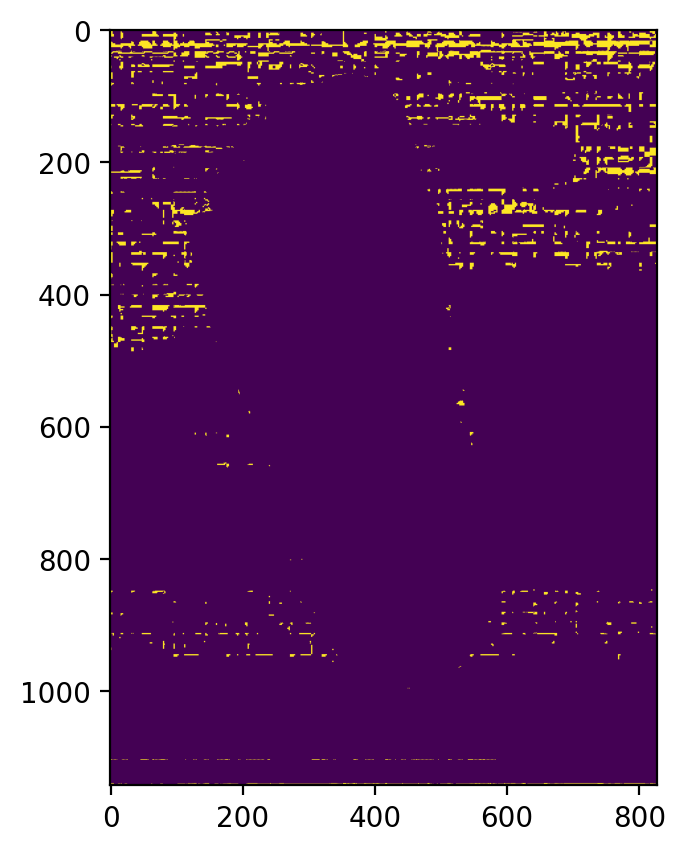

In [17]:
center = 150

width = 5
plt.imshow(((center - width) < h ) & (h < (center + width)))

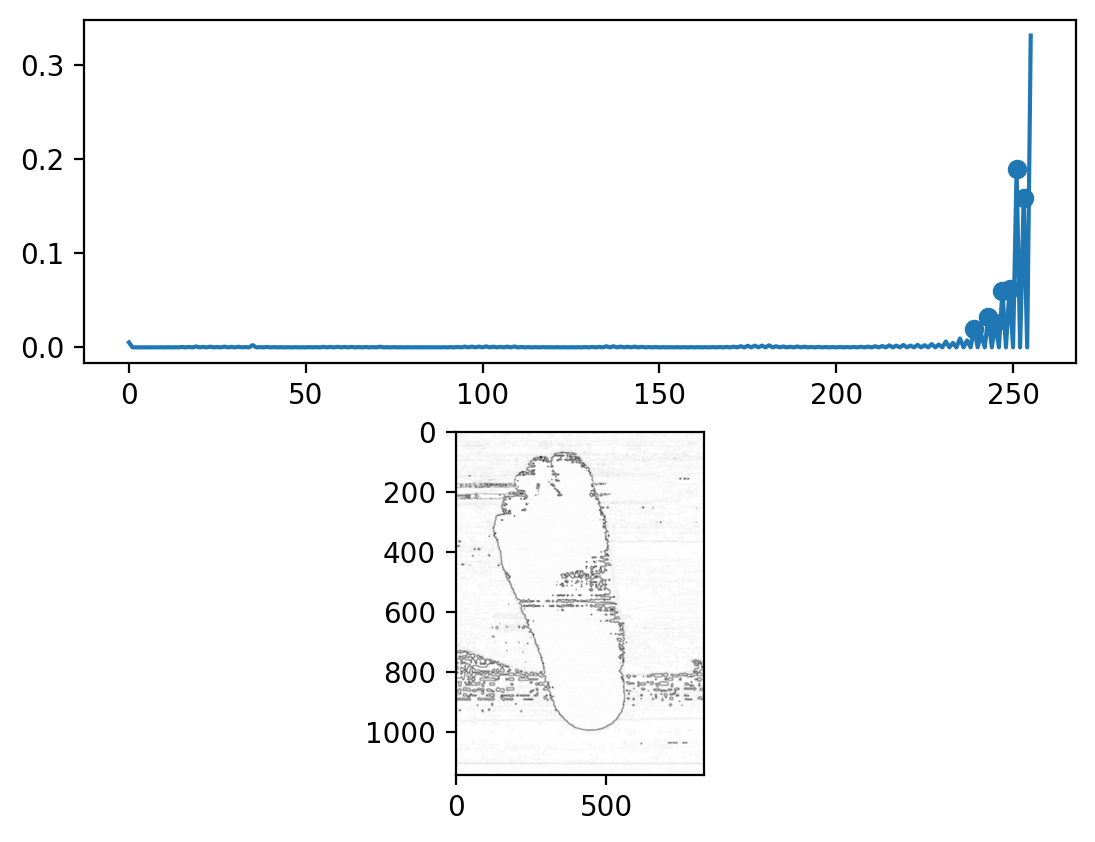

In [18]:
image3 = image.copy()

hsv = cv.cvtColor(image3, cv.COLOR_RGB2HSV)
h, s, v = hsv[...,0], hsv[...,1], hsv[...,2]

dim = 3
ksize = (dim, dim)
h = cv.GaussianBlur(h, ksize, 6)

dim = 3
hdiff = cv.Laplacian(h, cv.CV_16S, ksize=dim)

hdiff = cv.convertScaleAbs(hdiff)

fig, axs = plt.subplots(2)
# axs = axs.flatten()

# axs[0].imshow(h, 'gray')
hist, hist_centers = ski.exposure.histogram(~hdiff, normalize=True)

axs[0].plot(hist_centers, hist)
peaks, _ = sp.signal.find_peaks(hist, threshold=0.015,distance=1)


axs[0].scatter(peaks, hist[peaks])

axs[1].imshow(~hdiff, 'gray')

1 3
7
0 239
1 243
2 245
3 247
4 249
5 251
6 253


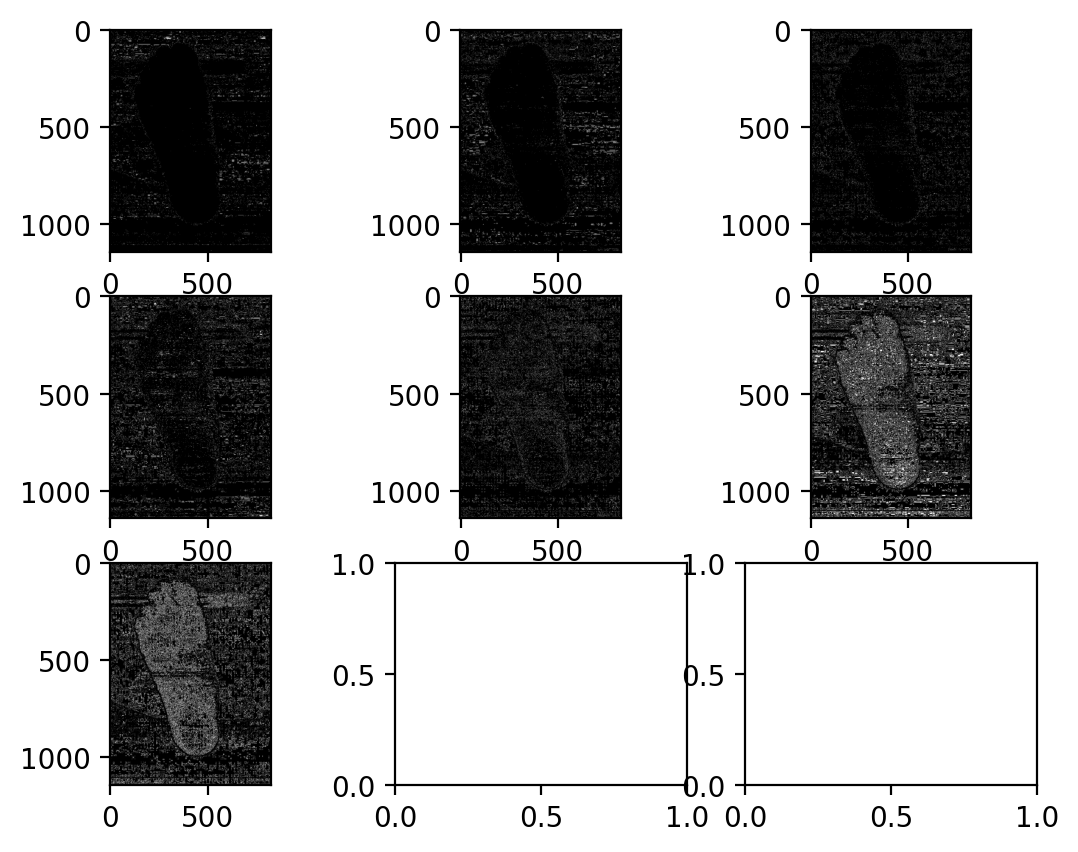

In [20]:
cols = len(peaks) % 4
rows = len(peaks) // 4
print(rows, cols)
print(len(peaks))

fig, axs = plt.subplots(3, 3)
axs = axs.flatten()

for i, peak in enumerate(peaks):
    print(i, peak)
    center = peak
    width = 2
    axs[i].imshow(((center - width) < ~hdiff ) & (~hdiff < (center + width)), 'gray')

In [21]:
def extract_bit_plane(image, bit_plane_n):
    """
    Extracts the specified bit plane from a grayscale image.

    Args:
        image (np.ndarray): The input grayscale image (uint8 dtype).
        bit_plane_n (int): The bit plane number to extract (0-7 for 8-bit image).

    Returns:
        np.ndarray: A binary image (0 or 255) representing the extracted bit plane.
    """
    # Create a mask with a 1 at the desired bit position
    mask = 1 << bit_plane_n

    # Apply bitwise AND to isolate the bits
    isolated_bits = image & mask

    # Convert the binary values (0 or 2^n) to a visible binary image (0 or 255)
    # This step is for visualization purposes
    bit_plane_image = (isolated_bits * 255 / mask).astype(np.uint8)

    return bit_plane_image

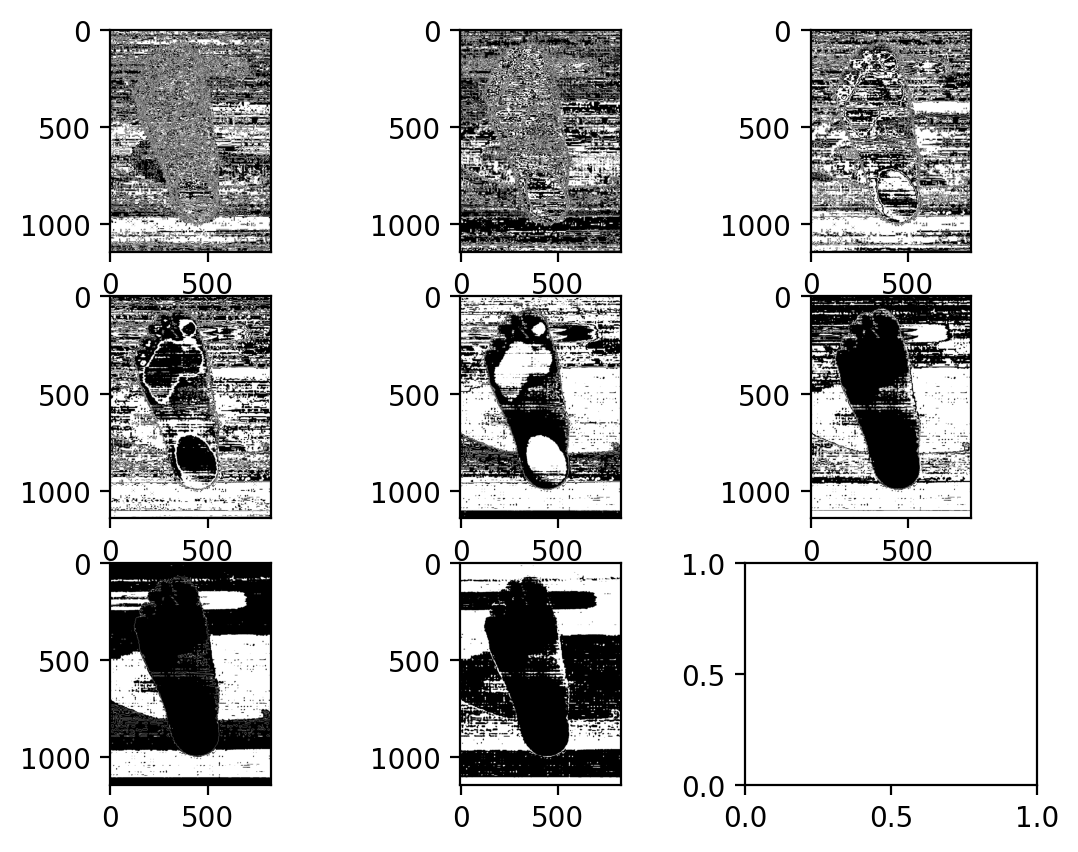

In [22]:
fig, axs = plt.subplots(3, 3)
axs = axs.flatten()

for i in range(0, 8):
    axs[i].imshow(extract_bit_plane(h, i), 'gray')

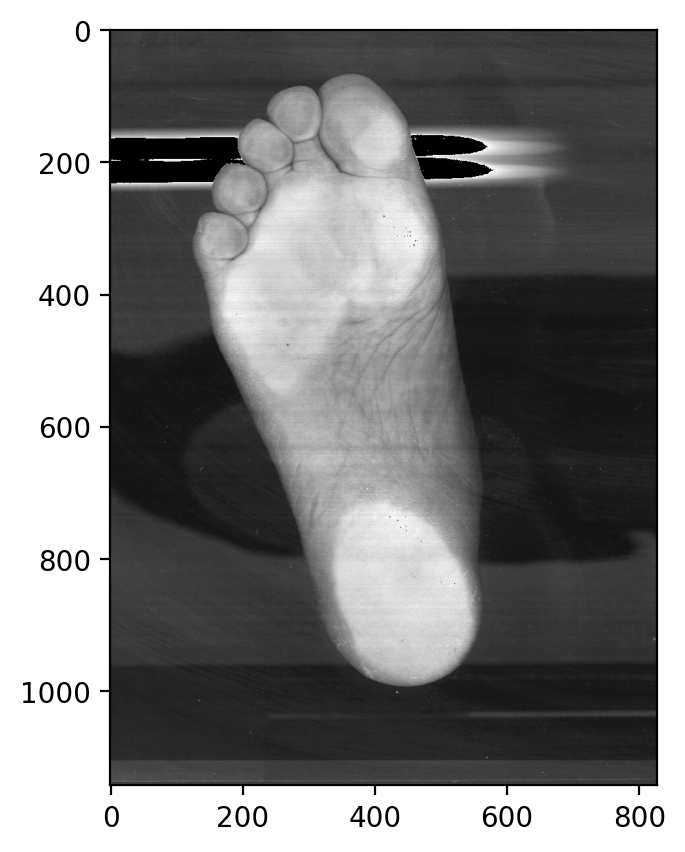

In [23]:
lab = cv.cvtColor(image3, cv.COLOR_RGB2Lab)
l, a, b = lab[...,0], lab[...,1], lab[...,2]

l[l > 170] = 0

plt.imshow(l, 'gray')